# Choose branch-specific resolution in a spatial taxonomy with GAUGE

**Your task.** Decide where the supplied labels justify another level of detail. On a fixed Allen Brain Cell Atlas MERFISH sample from the hippocampal formation (HPF), use expression to evaluate the `class → subclass → supertype` taxonomy. Compare the DG and VLMC branches, then map the selected resolution back to the measured cell positions.

This teaching asset contains 3,000 cells from the prespecified `x_ccf` interval 6.8–7.0 mm and 500 measured genes. The taxonomy assignments are supplied with the data. GAUGE chooses how far to retain the taxonomy on this sample.

## 0. Install GAUGE and place the data beside this notebook

Use Python 3.10 or newer. In a terminal on macOS or Linux, create and activate an environment.

```bash
python -m venv .venv
source .venv/bin/activate
```

In Windows PowerShell, activate it with `.venv\Scripts\Activate.ps1`.

Install the software and tutorial dependencies from the public GAUGE repository. If you already have a checkout, run the install command from its root.

```bash
git clone https://github.com/zhanglabtools/gauge-sc.git
cd gauge-sc
python -m pip install ".[tutorial]" jupyterlab
```

To install from a downloaded wheel, pass its local path with the tutorial extra. This example uses version `0.1.0a2`.

```bash
python -m pip install "./gauge_sc-0.1.0a2-py3-none-any.whl[tutorial]" jupyterlab
```

Download **`abc_hpf.h5ad`** (about 1.5 MB) from [tutorial-data-v1](https://github.com/zhanglabtools/gauge-sc/releases/tag/tutorial-data-v1) and put it beside this notebook. You can also run this command from the notebook folder.

```bash
curl -fLO https://github.com/zhanglabtools/gauge-sc/releases/download/tutorial-data-v1/abc_hpf.h5ad
```

From that folder, run `jupyter lab`, open this notebook and select the installed Python environment as its kernel. If you keep the file elsewhere, set `data_dir` below to its containing directory. GAUGE verifies the pinned local file. The first cell should print **3,000 cells × 500 features**.

In [1]:
import os
from pathlib import Path

import gauge_sc as gauge

data_dir = Path(os.environ.get("GAUGE_TUTORIAL_DATA") or ".")
adata = gauge.datasets.load_example("abc_hpf", data_dir=data_dir, download=False)
print(f"GAUGE {gauge.__version__} · {adata.n_obs:,} cells × {adata.n_vars:,} features")

GAUGE 0.1.0a2 · 3,000 cells × 500 features


## 1. Set up the supplied taxonomy and evaluate each possible split

The expression matrix already uses a log2 scale. Compute 30 principal components from the matrix as loaded. The labels in `obs` are nested from broad class to fine supertype, with one parent for each child label. The top-level classes are fixed roots. Coordinates in the Allen Common Coordinate Framework (CCF) are used later for display.

For an eligible parent, GAUGE uses five stratified folds to ask how well molecular features predict **which child each cell belongs to within that parent**. The conditional ITCA score uses only the cells and group proportions within that parent. A split must have at least two observed children and at least 10 cells in every child for the settings below. Ten refers to the child’s total cells. An ineligible split blocks deeper splits along that branch.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from IPython.display import display

sc.set_figure_params(dpi=110, frameon=False)
levels = ["class", "subclass", "supertype"]
display(adata.obs[[*levels, "y_ccf", "z_ccf"]].head(3))
sc.pp.pca(adata, n_comps=30, random_state=0)
evaluation = gauge.evaluate(
    adata, hierarchy=levels, views={"molecular": {"obsm": "X_pca"}},
    n_splits=5, random_state=0, aggregation="fold_mean", min_child_cells=10,
)

,class,subclass,supertype,y_ccf,z_ccf
1104095349101290374-2,30 Astro-Epen,319 Astro-TE NN,1161 Astro-TE NN_1,2.650024,3.193849
1104095349101460229-1,30 Astro-Epen,319 Astro-TE NN,1161 Astro-TE NN_1,2.661427,3.649432
1104095349101460252-3,30 Astro-Epen,319 Astro-TE NN,1161 Astro-TE NN_1,2.677977,3.679933


## 2. Compare the cost of keeping more groups

Splitting one parent into `k` children adds `k−1` groups. The immediate gain is **conditional ITCA − δ × (k−1)**. GAUGE keeps a split when its best allowed subtree has positive total gain. A parent must stay split to keep any descendant split. When the children are supertypes at the deepest supplied level, the immediate gain alone determines whether a scored split is worth keeping.

,delta,n_splits,n_groups,itca_plus_gain
0,0.00,6,20,2.793
1,0.05,6,20,2.343
2,0.15,5,19,1.527
3,0.30,2,14,0.540
4,0.60,0,11,0.000


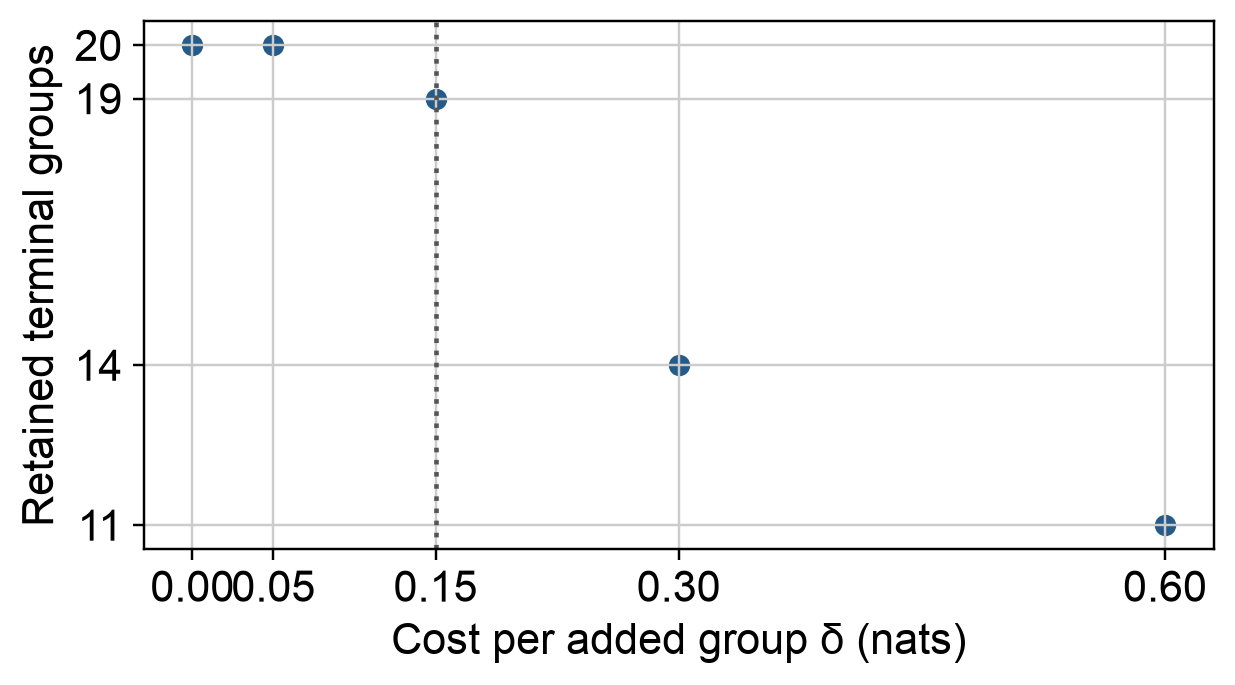

In [3]:
delta = 0.15
penalties = [0, 0.05, delta, 0.30, 0.60]
selection = gauge.select(evaluation, view="molecular", delta=penalties)
display(selection.path[["delta", "n_splits", "n_groups", "itca_plus_gain"]].round(3))
fig, ax = plt.subplots(figsize=(5.5, 3), layout="constrained")
ax.scatter(selection.path.delta, selection.path.n_groups, color="#245b88")
ax.axvline(delta, color="#555555", linestyle=":")
ax.set(
    xlabel="Cost per added group δ (nats)", ylabel="Retained terminal groups",
    xticks=penalties, yticks=sorted(selection.path.n_groups.unique()),
)
plt.show()

Each dot shows a tested penalty. The dotted line marks `δ=0.15`, which we use to inspect individual branches. A terminal group is the deepest label retained on its branch. One penalty can leave some cells at class, others at subclass, and others at supertype.

## 3. Read the DG, VLMC and CA3 decisions

Start with the smallest child count to check whether a split could be scored. For an eligible split, compare conditional ITCA with its added cost. A dash in the score and gain columns means the split was blocked before scoring.

In [4]:
decisions = selection.splits.loc[selection.splits["delta"].eq(delta)].copy()
branch_labels = ["037 DG Glut", "330 VLMC NN", "017 CA3 Glut"]
cases = decisions.set_index("label").loc[branch_labels].reset_index()
cases = cases.merge(
    evaluation.table[["node_id", "n_cells", "n_children", "min_child_size", "itca"]],
    on="node_id", validate="one_to_one",
)
cases["split_cost"] = (delta * (cases["n_children"] - 1)).where(cases["eligible"])
cases["decision"] = np.select(
    [~cases["eligible"], cases["accepted"]],
    ["Blocked before scoring", "Continue to supertype"],
    default="Stop after scoring",
)
for column in ("itca", "split_cost", "immediate_gain"):
    cases[column] = cases[column].map(lambda value: "—" if pd.isna(value) else f"{value:.3f}")
display(cases[[
    "label", "n_cells", "n_children", "min_child_size", "itca",
    "split_cost", "immediate_gain", "decision",
]].rename(columns={
    "label": "Subclass", "n_cells": "Cells", "n_children": "Observed children",
    "min_child_size": "Smallest child", "itca": "Conditional ITCA",
    "split_cost": "Split cost", "immediate_gain": "Immediate gain",
    "decision": "Decision at δ=0.15",
}))

,Subclass,Cells,Observed children,Smallest child,Conditional ITCA,Split cost,Immediate gain,Decision at δ=0.15
0,037 DG Glut,1093,2,36,0.066,0.150,-0.084,Stop after scoring
1,330 VLMC NN,26,2,13,0.312,0.150,0.162,Continue to supertype
2,017 CA3 Glut,281,4,7,—,—,—,Blocked before scoring


- **DG Glut stops at subclass after scoring.** Its two children contain 1,057 and 36 cells. Both meet the support rule, so GAUGE can estimate the conditional ITCA. The molecular score falls below the 0.15 nat cost of adding one group, so the 1,093 cells keep the subclass label `037 DG Glut`.
- **VLMC NN continues to supertype.** Its two children contain 13 cells each. Both meet the support rule, and the molecular score exceeds the same 0.15 nat cost. The 26 cells retain their two supplied supertype labels.
- **CA3 Glut stops because of cell support.** There are 281 cells in the parent, but its smallest observed child has only 7. That child blocks the split before cross-validation, so the branch has no ITCA or gain to compare with the cost. Changing `δ` only changes decisions for splits that can be scored.

A branch with just one observed child also stops before scoring. A branch at the deepest supplied level is already a leaf. These cases explain why terminal labels may appear at different depths on the same map.

## 4. Map the selected resolution back to the tissue

Write the chosen labels to this in-memory example, count cells by terminal level and plot the original class, selected identity and selected level on the same coordinates. Identity palettes assign a distinct color to every observed label in their own panel. The level palette deliberately shares a color across cells at the same depth.

In [5]:
selection.write_to_adata(adata, delta=delta, key_added="adaptive")
terminals = decisions.loc[decisions["terminal"]]
assignments = selection.assignments.loc[selection.assignments["delta"].eq(delta)]
node_for_cell = assignments.set_index("obs_name")["node_id"].reindex(adata.obs_names)
levels_by_node = decisions.set_index("node_id")["level"]
adata.obs["selected_level"] = pd.Categorical(
    node_for_cell.map(levels_by_node), categories=levels, ordered=True,
)
display(pd.DataFrame({
    "Terminal groups": terminals["level"].value_counts().reindex(levels, fill_value=0),
    "Cells": adata.obs["selected_level"].value_counts().reindex(levels, fill_value=0),
}))

,Terminal groups,Cells
class,7,819
subclass,10,2155
supertype,2,26


class: 11 observed labels, 11 distinct colors.
adaptive: 19 observed labels, 19 distinct colors.


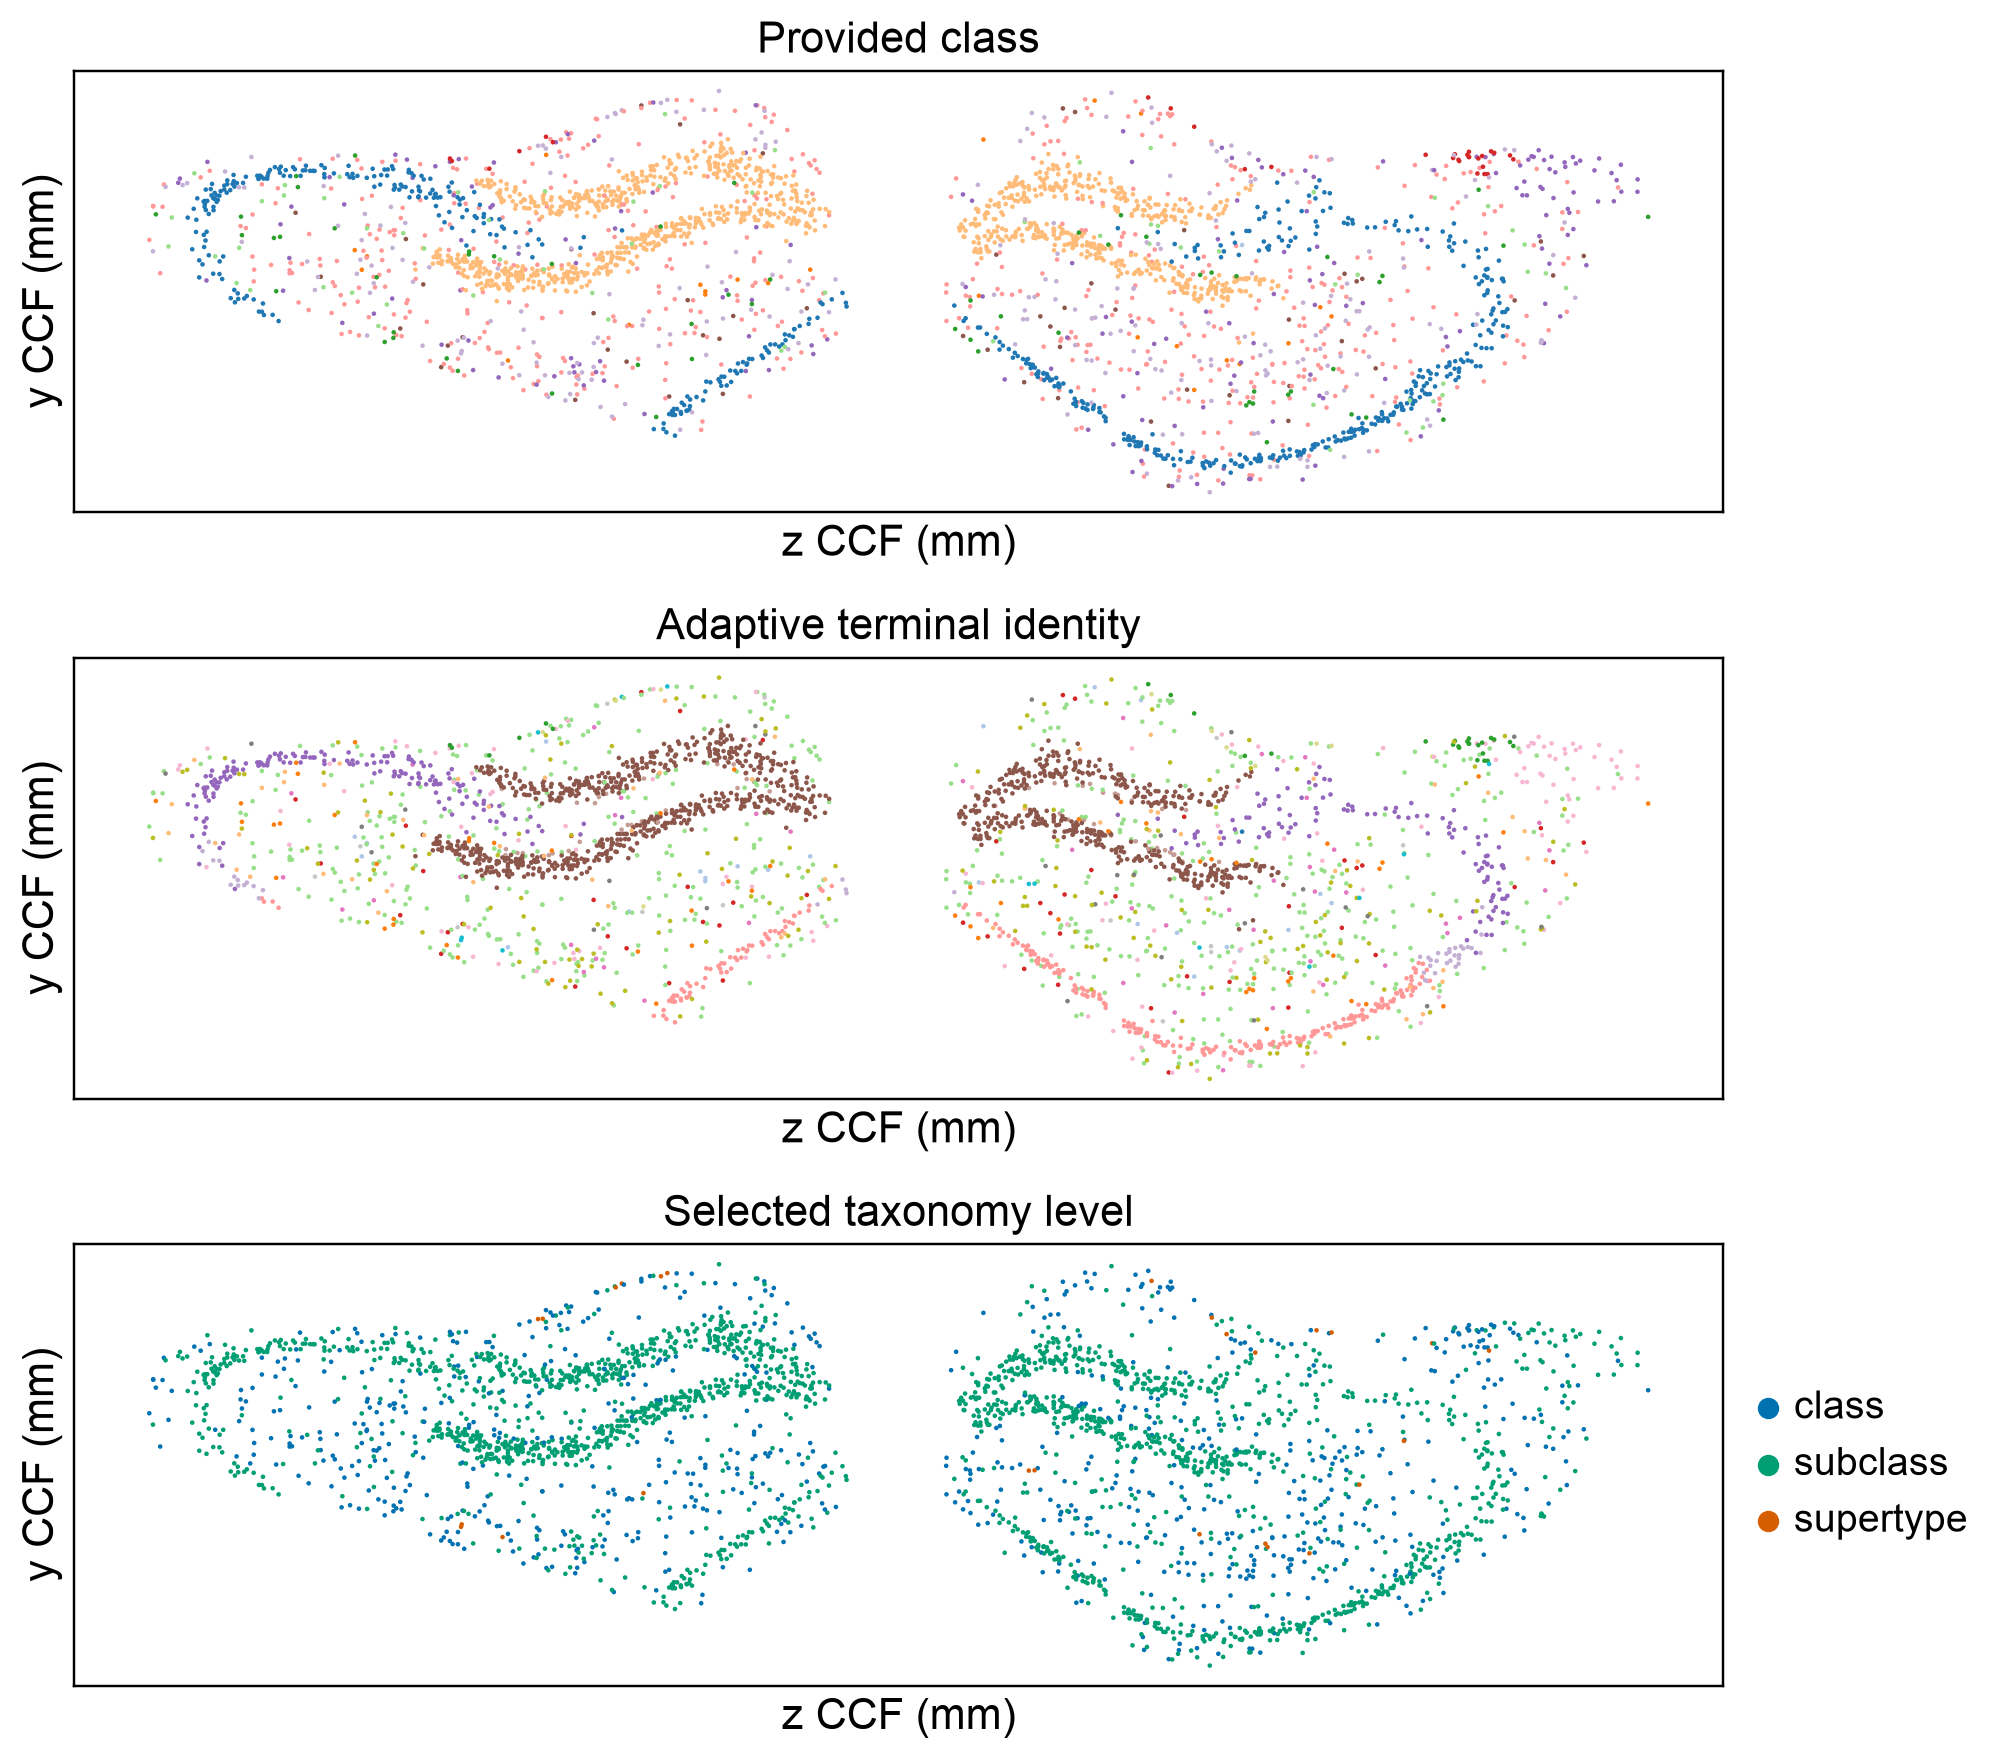

In [6]:
import seaborn as sns

# Plot a copy: remove unused categories and assign one color per actual identity.
plot_data = adata.copy()
identity_palettes = {}
for identity_key in ["class", "adaptive"]:
    plot_data.obs[identity_key] = (
        plot_data.obs[identity_key].astype("category").cat.remove_unused_categories()
    )
    categories = plot_data.obs[identity_key].cat.categories
    colors = (sc.pl.palettes.vega_20[:len(categories)] if len(categories) <= 20
              else sns.color_palette("husl", n_colors=len(categories)).as_hex())
    if len(set(colors)) != len(categories):
        raise ValueError(f"Expected one distinct color per observed {identity_key} label.")
    identity_palettes[identity_key] = dict(zip(categories, colors))
    print(f"{identity_key}: {len(categories)} observed labels, {len(set(colors))} distinct colors.")

# Use the same cell coordinates and geometry in all panels.
# Horizontal z_ccf, vertical y_ccf; retain equal physical axis scaling.
plot_data.obsm["spatial_display"] = plot_data.obs[["z_ccf", "y_ccf"]].to_numpy()
level_palette = {"class": "#0072B2", "subclass": "#009E73", "supertype": "#D55E00"}
fig, axes = plt.subplots(3, 1, figsize=(9, 8), layout="constrained")
for ax, key, title in zip(axes, ["class", "adaptive", "selected_level"],
                          ["Provided class", "Adaptive terminal identity", "Selected taxonomy level"]):
    sc.pl.embedding(
        plot_data, basis="spatial_display", color=key, ax=ax, show=False,
        palette=level_palette if key == "selected_level" else identity_palettes[key],
        legend_loc="right margin" if key == "selected_level" else "none",
        size=9, title=title, frameon=True,
    )
    ax.set(xlabel="z CCF (mm)", ylabel="y CCF (mm)", aspect="equal")
    ax.invert_xaxis()
plt.show()

**Read the maps.** The first panel shows the broad supplied classes, the second shows the retained terminal identities, and the third shows how far each cell’s branch was resolved. The coordinates and scaling are identical across panels. Use the decision table to tell whether a broad label reflects a scored stop or an eligibility constraint. The map shows where those choices occur.

## Apply the selection to your own AnnData

Supply one AnnData object with nested label columns from broad to fine in `obs` and a molecular representation in `obsm`. Each observed child label should identify exactly one parent. Change the input, three taxonomy column names, embedding key, and decision settings below. The snippet runs as written on the example data. It returns labels without writing them to your object. Supply measured spatial coordinates separately if you want to map them.

In [7]:
user_adata = adata  # Replace with sc.read_h5ad("my_spatial_sample.h5ad").
taxonomy = ["class", "subclass", "supertype"]  # Your nested columns in .obs.
embedding = "X_pca"  # Your molecular representation in .obsm.
minimum_child_cells, target_delta = 10, 0.15

user_evaluation = gauge.evaluate(
    user_adata, hierarchy=taxonomy, views={"molecular": {"obsm": embedding}},
    n_splits=5, random_state=0, aggregation="fold_mean",
    min_child_cells=minimum_child_cells,
)
user_selection = gauge.select(user_evaluation, view="molecular", delta=target_delta)
display(user_selection.assignments[["obs_name", "label"]].head())

,obs_name,label
0,1104095349101290374-2,class: 30 Astro-Epen
1,1104095349101460229-1,class: 30 Astro-Epen
2,1104095349101460252-3,class: 30 Astro-Epen
3,1104095349101290525-1,class: 30 Astro-Epen
4,1104095349201290495,class: 30 Astro-Epen


## Go further

[Paper reproduction](../../docs/paper-reproduction.md) tracks the full Figure 6 analysis and its spatial and QC control views. The tutorial selects from the supplied labels on one teaching slice using molecular evidence.

[Use GAUGE with your agent](../../docs/agents.md) with the `abc_hpf` tutorial data. Ask it to show one branch that stops after scoring, one that continues, and one that fails the minimum child support rule. Then ask it to map the retained taxonomy levels on the same coordinates.